In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


In [4]:
from pathlib import Path

dataset_path = Path("../archive")

for folder in ["train/REAL", "train/FAKE",
               "test/REAL", "test/FAKE"]:

    path = dataset_path / folder

    if path.exists():
        total = len(list(path.glob("*")))
        print(f"{folder}: {total} file")
    else:
        print(f"{folder}: Folder tidak ditemukan")

train/REAL: 51809 file
train/FAKE: 50000 file
test/REAL: 10000 file
test/FAKE: 10000 file


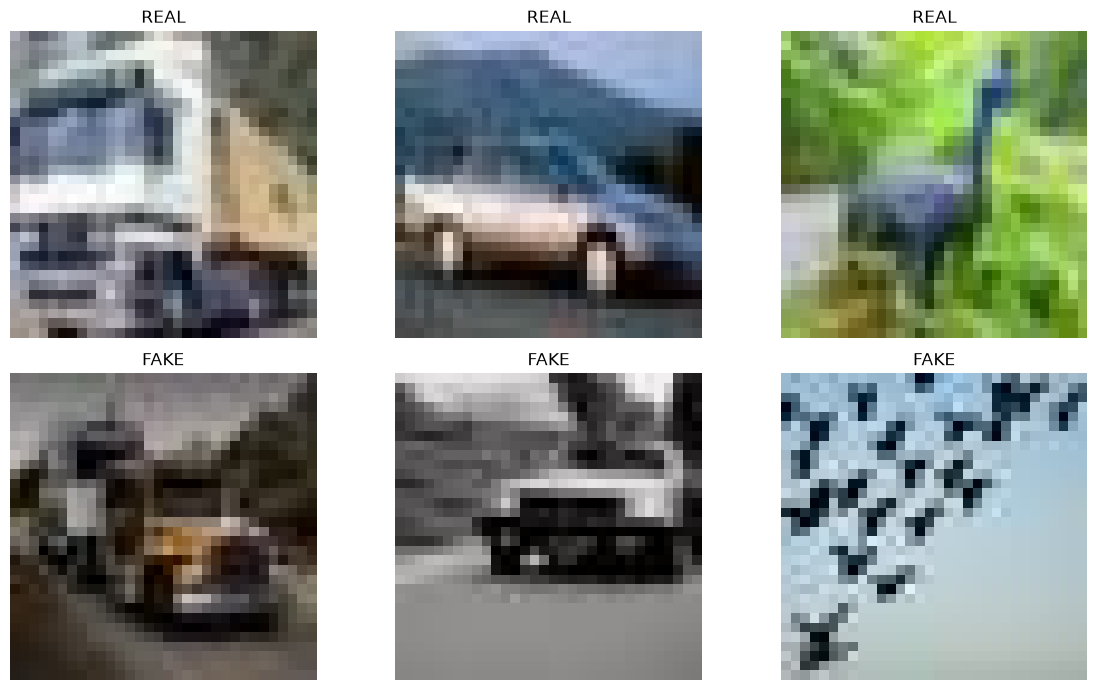

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for row, label in enumerate(["REAL", "FAKE"]):
    folder = dataset_path / "train" / label

    images = list(folder.glob("*.jpg"))[:3]

    for col, image_path in enumerate(images):
        img = Image.open(image_path)

        axes[row, col].imshow(img)
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [9]:
from pathlib import Path

# Arahkan ke folder train
real_dir = Path("../archive/train/REAL")
fake_dir = Path("../archive/train/FAKE")

# Ambil daftar semua filenya
all_real = sorted(list(real_dir.glob("*.jpg")))
all_fake = sorted(list(fake_dir.glob("*.jpg")))

print("Jumlah foto REAL mentah:", len(all_real))
print("Jumlah foto FAKE mentah:", len(all_fake))

Jumlah foto REAL mentah: 50000
Jumlah foto FAKE mentah: 50000


In [10]:
import random

# Kunci angka acak agar hasilnya konsisten
random.seed(42)

# Ambil masing-masing 2000 foto secara acak
sample_real = random.sample(all_real, 2000)
sample_fake = random.sample(all_fake, 2000)

print("Sampel REAL yang diambil:", len(sample_real))
print("Sampel FAKE yang diambil:", len(sample_fake))
print("Total sampel terkurasi:", len(sample_real) + len(sample_fake))

Sampel REAL yang diambil: 2000
Sampel FAKE yang diambil: 2000
Total sampel terkurasi: 4000


Nama file    : 4190 (6).jpg
Ukuran (px)  : (32, 32)
Format       : JPEG
Mode warna   : RGB
Ukuran file  : 0.94 KB


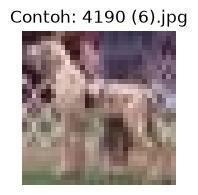

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

# Ambil 1 foto contoh dari sampel REAL
contoh_path = sample_real[0]

# Buka fotonya
img = Image.open(contoh_path)

# Tampilkan informasi metadatanya
print("Nama file    :", contoh_path.name)
print("Ukuran (px)  :", img.size)          # (lebar, tinggi)
print("Format       :", img.format)        # JPEG
print("Mode warna   :", img.mode)          # RGB
print("Ukuran file  :", round(contoh_path.stat().st_size / 1024, 2), "KB")

# Tampilkan fotonya di layar
plt.figure(figsize=(2, 2))
plt.imshow(img)
plt.title(f"Contoh: {contoh_path.name}")
plt.axis("off")
plt.show()

In [12]:
import pandas as pd
from tqdm import tqdm

metadata_list = []

# Gabungkan sampel REAL dan FAKE dengan labelnya
semua_sampel = [("REAL", path) for path in sample_real] + [("FAKE", path) for path in sample_fake]

# Loop untuk membaca metadata setiap foto
for label, img_path in tqdm(semua_sampel, desc="Mengumpulkan Metadata"):
    with Image.open(img_path) as img:
        width, height = img.size
        size_kb = img_path.stat().st_size / 1024
        
        metadata_list.append({
            "filename": img_path.name,
            "filepath": str(img_path),
            "label": label,
            "width": width,
            "height": height,
            "format": img.format,
            "file_size_kb": round(size_kb, 3)
        })

# Simpan hasilnya ke dalam DataFrame (Tabel Pandas)
df_metadata = pd.DataFrame(metadata_list)
print("Selesai! Total data yang terkumpul di tabel:", len(df_metadata))

Mengumpulkan Metadata: 100%|██████████| 4000/4000 [00:02<00:00, 1720.59it/s]

Selesai! Total data yang terkumpul di tabel: 4000


In [13]:
# 1. Tampilkan 5 baris pertama tabel
print("=== 5 CONTOH DATA TERATAS ===")
display(df_metadata.head())

# 2. Cek apakah resolusi dan format semua foto seragam
print("\n=== INFORMASI RESOLUSI & FORMAT ===")
print("Resolusi gambar (lebar x tinggi) :", df_metadata['width'].unique(), "x", df_metadata['height'].unique())
print("Format file gambar               :", df_metadata['format'].unique())

# 3. Bandingkan ringkasan ukuran file (KB) antara REAL vs FAKE
print("\n=== PERBANDINGAN UKURAN FILE (KB) ===")
perbandingan_ukuran = df_metadata.groupby("label")["file_size_kb"].agg(["count", "mean", "std", "min", "max"])
display(perbandingan_ukuran)

=== 5 CONTOH DATA TERATAS ===


,filename,filepath,label,width,height,format,file_size_kb
0,4190 (6).jpg,..\archive\train\REAL\4190 (6).jpg,REAL,32,32,JPEG,0.938
1,0729 (7).jpg,..\archive\train\REAL\0729 (7).jpg,REAL,32,32,JPEG,0.902
2,0163.jpg,..\archive\train\REAL\0163.jpg,REAL,32,32,JPEG,0.931
3,4859 (9).jpg,..\archive\train\REAL\4859 (9).jpg,REAL,32,32,JPEG,0.988
4,1802 (5).jpg,..\archive\train\REAL\1802 (5).jpg,REAL,32,32,JPEG,0.916



=== INFORMASI RESOLUSI & FORMAT ===
Resolusi gambar (lebar x tinggi) : [32] x [32]
Format file gambar               : <ArrowStringArray>
['JPEG']
Length: 1, dtype: str

=== PERBANDINGAN UKURAN FILE (KB) ===


,count,mean,std,min,max
label,,,,,
FAKE,2000,0.903210,0.061602,0.699,1.082
REAL,2000,0.901301,0.052455,0.720,1.046


C:\Users\mrest\AppData\Local\Temp\ipykernel_19228\138632786.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_metadata, x="label", y="file_size_kb",


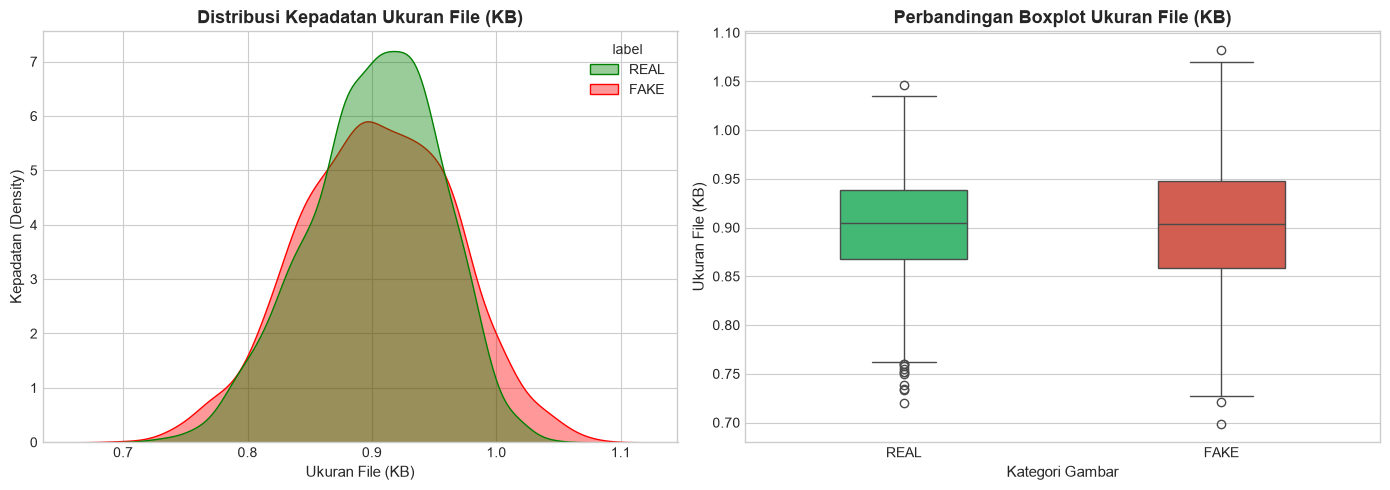

Grafik berhasil disimpan di: C:\restu\intern 1\detection_image\outputs\visualizations\01_file_size_distribution.png


In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Pastikan folder outputs/visualizations ada
output_viz_dir = Path("../outputs/visualizations")
output_viz_dir.mkdir(parents=True, exist_ok=True)

# Set gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Grafik Distribusi (KDE Plot / Histogram kurva)
sns.kdeplot(data=df_metadata, x="file_size_kb", hue="label", fill=True, common_norm=False, 
            palette={"REAL": "green", "FAKE": "red"}, alpha=0.4, ax=axes[0])
axes[0].set_title("Distribusi Kepadatan Ukuran File (KB)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Ukuran File (KB)", fontsize=11)
axes[0].set_ylabel("Kepadatan (Density)", fontsize=11)

# 2. Grafik Boxplot
sns.boxplot(data=df_metadata, x="label", y="file_size_kb", 
            palette={"REAL": "#2ecc71", "FAKE": "#e74c3c"}, width=0.4, ax=axes[1])
axes[1].set_title("Perbandingan Boxplot Ukuran File (KB)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Kategori Gambar", fontsize=11)
axes[1].set_ylabel("Ukuran File (KB)", fontsize=11)

plt.tight_layout()

# Simpan grafik secara otomatis ke folder outputs/visualizations
save_path = output_viz_dir / "01_file_size_distribution.png"
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Grafik berhasil disimpan di: {save_path.resolve()}")

In [15]:
import numpy as np
import cv2

# Ambil 1 foto contoh
sample_img_path = df_metadata.iloc[0]["filepath"]
img_pil = Image.open(sample_img_path)

# Ubah gambar ke array angka (matriks piksel)
img_array = np.array(img_pil)

# 1. Ekstrak R, G, B
r_channel = img_array[:, :, 0]
g_channel = img_array[:, :, 1]
b_channel = img_array[:, :, 2]

# 2. Ekstrak HSV (Hue, Saturation, Value/Brightness)
img_hsv = cv2.cvtColor(img_array, cv2.COLOR_RGB2HSV)
saturation = img_hsv[:, :, 1]
brightness = img_hsv[:, :, 2]

print("=== CONTOH FITUR WARNA DARI 1 FOTO ===")
print("Rata-rata Merah (R Mean) :", round(r_channel.mean(), 2))
print("Rata-rata Hijau (G Mean) :", round(g_channel.mean(), 2))
print("Rata-rata Biru (B Mean)  :", round(b_channel.mean(), 2))
print("Rata-rata Kejenuhan (Sat):", round(saturation.mean(), 2))
print("Rata-rata Kecerahan (Val):", round(brightness.mean(), 2))

=== CONTOH FITUR WARNA DARI 1 FOTO ===
Rata-rata Merah (R Mean) : 133.73
Rata-rata Hijau (G Mean) : 113.49
Rata-rata Biru (B Mean)  : 110.25
Rata-rata Kejenuhan (Sat): 61.41
Rata-rata Kecerahan (Val): 135.33


In [16]:
color_features_list = []

for idx, row in tqdm(df_metadata.iterrows(), total=len(df_metadata), desc="Ekstraksi Fitur Warna"):
    img_array = np.array(Image.open(row["filepath"]))
    
    # 1. Saluran RGB
    r = img_array[:, :, 0]
    g = img_array[:, :, 1]
    b = img_array[:, :, 2]
    
    # 2. Ruang warna HSV untuk kejenuhan & kecerahan
    hsv = cv2.cvtColor(img_array, cv2.COLOR_RGB2HSV)
    sat = hsv[:, :, 1]
    val = hsv[:, :, 2]
    
    color_features_list.append({
        "red_mean": round(r.mean(), 2),
        "red_std": round(r.std(), 2),
        "green_mean": round(g.mean(), 2),
        "green_std": round(g.std(), 2),
        "blue_mean": round(b.mean(), 2),
        "blue_std": round(b.std(), 2),
        "brightness_mean": round(val.mean(), 2),
        "saturation_mean": round(sat.mean(), 2)
    })

# Gabungkan fitur warna ini ke dalam tabel utama kita
df_color = pd.DataFrame(color_features_list)
df_features = pd.concat([df_metadata, df_color], axis=1)

print("Ekstraksi warna selesai! Kolom tabel sekarang:")
print(list(df_features.columns))

Ekstraksi Fitur Warna: 100%|██████████| 4000/4000 [00:04<00:00, 804.02it/s]

Ekstraksi warna selesai! Kolom tabel sekarang:
['filename', 'filepath', 'label', 'width', 'height', 'format', 'file_size_kb', 'red_mean', 'red_std', 'green_mean', 'green_std', 'blue_mean', 'blue_std', 'brightness_mean', 'saturation_mean']


In [17]:
# Hitung rata-rata fitur warna berdasarkan label (REAL vs FAKE)
fitur_warna = ['red_mean', 'green_mean', 'blue_mean', 'brightness_mean', 'saturation_mean']

perbandingan_warna = df_features.groupby("label")[fitur_warna].mean()

print("=== PERBANDINGAN RATA-RATA FITUR WARNA ===")
display(perbandingan_warna)

# Hitung selisih perbedaannya
selisih = perbandingan_warna.loc["FAKE"] - perbandingan_warna.loc["REAL"]
print("\n=== SELISIH (FAKE dikurangi REAL) ===")
print("Positif (+) artinya nilai FAKE lebih tinggi, Negatif (-) artinya REAL lebih tinggi:")
display(selisih.round(2))

=== PERBANDINGAN RATA-RATA FITUR WARNA ===


,red_mean,green_mean,blue_mean,brightness_mean,saturation_mean
label,,,,,
FAKE,115.794975,113.412620,98.824705,129.493885,92.728500
REAL,125.999400,123.262565,112.710720,137.053340,72.067265



=== SELISIH (FAKE dikurangi REAL) ===
Positif (+) artinya nilai FAKE lebih tinggi, Negatif (-) artinya REAL lebih tinggi:


red_mean          -10.20
green_mean         -9.85
blue_mean         -13.89
brightness_mean    -7.56
saturation_mean    20.66
dtype: float64

C:\Users\mrest\AppData\Local\Temp\ipykernel_19228\4157797559.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x="label", y="saturation_mean",


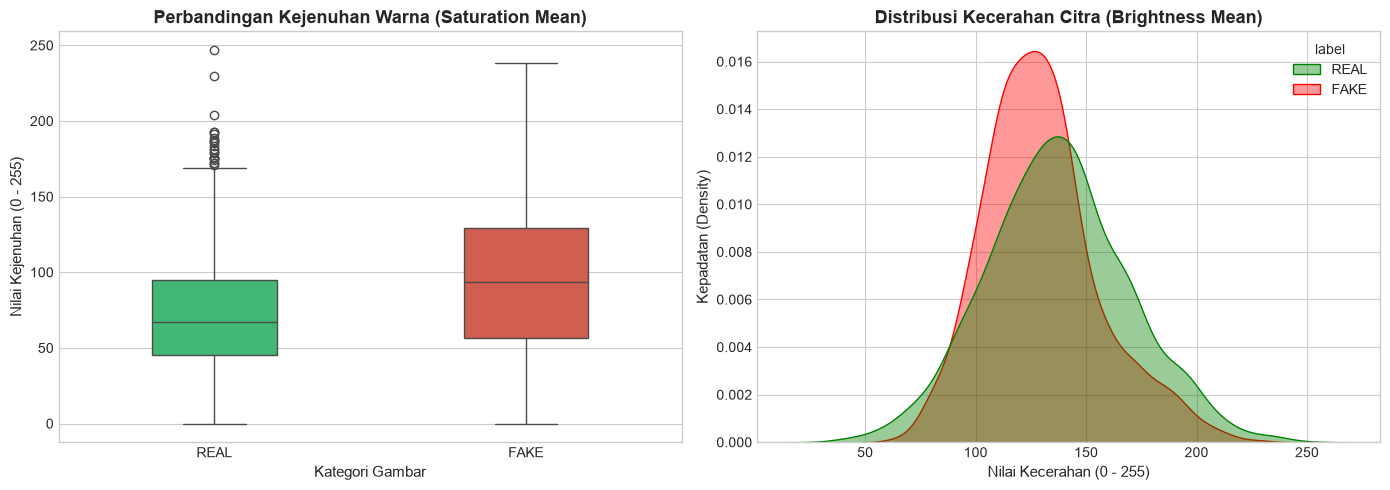

Grafik kedua berhasil disimpan di: C:\restu\intern 1\detection_image\outputs\visualizations\02_color_saturation_distribution.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot Perbandingan Kejenuhan Warna (Saturation)
sns.boxplot(data=df_features, x="label", y="saturation_mean", 
            palette={"REAL": "#2ecc71", "FAKE": "#e74c3c"}, width=0.4, ax=axes[0])
axes[0].set_title("Perbandingan Kejenuhan Warna (Saturation Mean)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Kategori Gambar", fontsize=11)
axes[0].set_ylabel("Nilai Kejenuhan (0 - 255)", fontsize=11)

# 2. KDE Plot Distribusi Kecerahan (Brightness)
sns.kdeplot(data=df_features, x="brightness_mean", hue="label", fill=True, common_norm=False,
            palette={"REAL": "green", "FAKE": "red"}, alpha=0.4, ax=axes[1])
axes[1].set_title("Distribusi Kecerahan Citra (Brightness Mean)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Nilai Kecerahan (0 - 255)", fontsize=11)
axes[1].set_ylabel("Kepadatan (Density)", fontsize=11)

plt.tight_layout()

# Simpan grafik secara otomatis
save_path_color = output_viz_dir / "02_color_saturation_distribution.png"
plt.savefig(save_path_color, dpi=300)
plt.show()

print(f"Grafik kedua berhasil disimpan di: {save_path_color.resolve()}")

In [19]:
from skimage.feature import graycomatrix, graycoprops
import cv2

# Ambil 1 foto contoh dan ubah ke skala abu-abu (Grayscale)
sample_img = cv2.imread(df_features.iloc[0]["filepath"])
gray = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)

# 1. Hitung Matriks Tekstur GLCM (jarak 1 piksel, sudut 0 derajat)
glcm = graycomatrix(gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
contrast = graycoprops(glcm, 'contrast')[0, 0]
homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
energy = graycoprops(glcm, 'energy')[0, 0]
correlation = graycoprops(glcm, 'correlation')[0, 0]

# 2. Hitung Ketajaman / Blur dengan Variansi Laplacian
laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

print("=== CONTOH FITUR TEKSTUR & KETAJAMAN DARI 1 FOTO ===")
print("GLCM Contrast (Kekasaran Tekstur)    :", round(contrast, 2))
print("GLCM Homogeneity (Kehalusan Tekstur) :", round(homogeneity, 4))
print("GLCM Energy (Keseragaman Pola)       :", round(energy, 4))
print("GLCM Correlation (Korelasi Piksel)   :", round(correlation, 4))
print("Laplacian Variance (Tingkat Ketajaman):", round(laplacian_var, 2))

=== CONTOH FITUR TEKSTUR & KETAJAMAN DARI 1 FOTO ===
GLCM Contrast (Kekasaran Tekstur)    : 922.94
GLCM Homogeneity (Kehalusan Tekstur) : 0.0693
GLCM Energy (Keseragaman Pola)       : 0.025
GLCM Correlation (Korelasi Piksel)   : 0.7273
Laplacian Variance (Tingkat Ketajaman): 4681.21


In [20]:
from pathlib import Path

texture_features_list = []

for idx, row in tqdm(df_features.iterrows(), total=len(df_features), desc="Ekstraksi Fitur Tekstur"):
    # Baca gambar dalam grayscale
    img_gray = cv2.imread(row["filepath"], cv2.IMREAD_GRAYSCALE)
    
    # 1. Hitung GLCM (jarak 1, sudut 0)
    glcm = graycomatrix(img_gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    
    # 2. Hitung Fitur Tekstur GLCM
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    
    # 3. Hitung Ketajaman Citra (Laplacian Variance)
    lap_var = cv2.Laplacian(img_gray, cv2.CV_64F).var()
    
    texture_features_list.append({
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 4),
        "glcm_energy": round(energy, 4),
        "glcm_correlation": round(correlation, 4),
        "laplacian_var": round(lap_var, 2)
    })

# Gabungkan ke tabel utama
df_texture = pd.DataFrame(texture_features_list)
df_features = pd.concat([df_features, df_texture], axis=1)

# Simpan tabel lengkap ke file CSV di folder outputs/extracted_features
features_dir = Path("../outputs/extracted_features")
features_dir.mkdir(parents=True, exist_ok=True)
csv_save_path = features_dir / "dataset_features_4000.csv"
df_features.to_csv(csv_save_path, index=False)

print(f"\nSelesai! Dataset fitur berhasil diekstrak dan disimpan di:")
print(csv_save_path.resolve())
print(f"Total baris: {len(df_features)} | Total kolom: {len(df_features.columns)}")

Ekstraksi Fitur Tekstur: 100%|██████████| 4000/4000 [00:18<00:00, 219.04it/s]



Selesai! Dataset fitur berhasil diekstrak dan disimpan di:
C:\restu\intern 1\detection_image\outputs\extracted_features\dataset_features_4000.csv
Total baris: 4000 | Total kolom: 20


In [21]:
# Daftar fitur tekstur dan ketajaman
fitur_tekstur = ['glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation', 'laplacian_var']

# 1. Hitung rata-rata untuk REAL dan FAKE
perbandingan_tekstur = df_features.groupby("label")[fitur_tekstur].mean()

print("=== PERBANDINGAN RATA-RATA FITUR TEKSTUR & KETAJAMAN ===")
display(perbandingan_tekstur)

# 2. Hitung selisih perbedaannya
selisih_tekstur = perbandingan_tekstur.loc["FAKE"] - perbandingan_tekstur.loc["REAL"]
print("\n=== SELISIH (FAKE dikurangi REAL) ===")
print("Positif (+) artinya FAKE lebih tinggi, Negatif (-) artinya REAL lebih tinggi:")
display(selisih_tekstur.round(4))

=== PERBANDINGAN RATA-RATA FITUR TEKSTUR & KETAJAMAN ===


,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation,laplacian_var
label,,,,,
FAKE,643.854785,0.184123,0.038203,0.877594,3804.07081
REAL,539.598155,0.144111,0.038048,0.884979,2500.09192



=== SELISIH (FAKE dikurangi REAL) ===
Positif (+) artinya FAKE lebih tinggi, Negatif (-) artinya REAL lebih tinggi:


glcm_contrast        104.2566
glcm_homogeneity       0.0400
glcm_energy            0.0002
glcm_correlation      -0.0074
laplacian_var       1303.9789
dtype: float64

C:\Users\mrest\AppData\Local\Temp\ipykernel_19228\1260013105.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x="label", y="glcm_contrast",


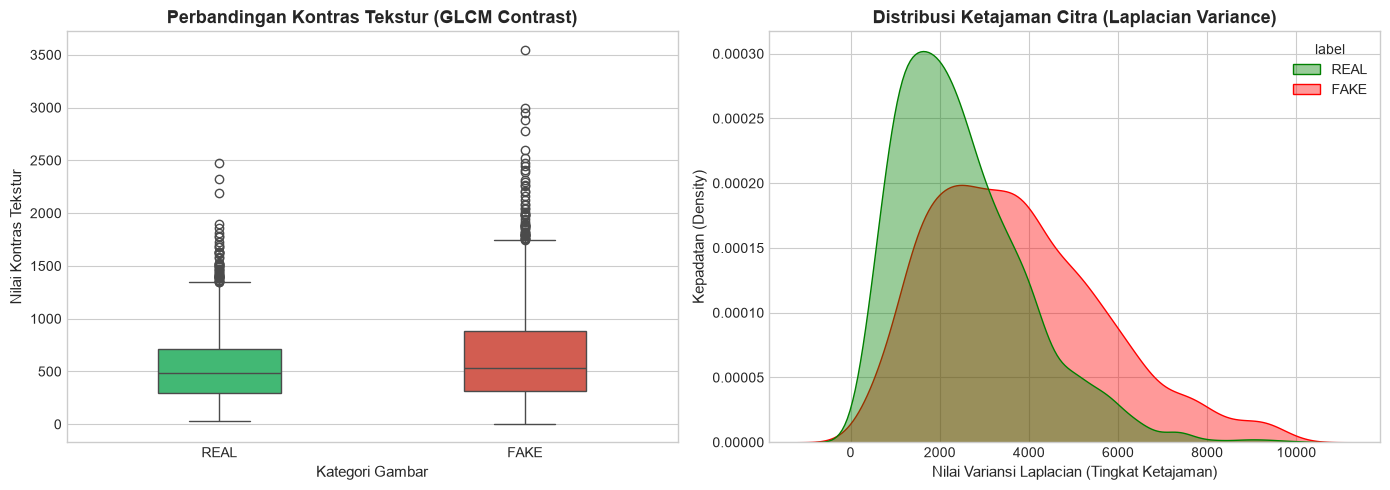

Grafik ketiga berhasil disimpan di: C:\restu\intern 1\detection_image\outputs\visualizations\03_texture_glcm_distribution.png


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot Perbandingan Kontras Tekstur GLCM
sns.boxplot(data=df_features, x="label", y="glcm_contrast", 
            palette={"REAL": "#2ecc71", "FAKE": "#e74c3c"}, width=0.4, ax=axes[0])
axes[0].set_title("Perbandingan Kontras Tekstur (GLCM Contrast)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Kategori Gambar", fontsize=11)
axes[0].set_ylabel("Nilai Kontras Tekstur", fontsize=11)

# 2. KDE Plot Distribusi Ketajaman (Laplacian Variance)
# (Kita batasi sumbu x di angka 10.000 agar grafik fokus di rentang mayoritas data)
sns.kdeplot(data=df_features[df_features["laplacian_var"] < 10000], x="laplacian_var", hue="label", 
            fill=True, common_norm=False, palette={"REAL": "green", "FAKE": "red"}, alpha=0.4, ax=axes[1])
axes[1].set_title("Distribusi Ketajaman Citra (Laplacian Variance)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Nilai Variansi Laplacian (Tingkat Ketajaman)", fontsize=11)
axes[1].set_ylabel("Kepadatan (Density)", fontsize=11)

plt.tight_layout()

# Simpan grafik secara otomatis
save_path_texture = output_viz_dir / "03_texture_glcm_distribution.png"
plt.savefig(save_path_texture, dpi=300)
plt.show()

print(f"Grafik ketiga berhasil disimpan di: {save_path_texture.resolve()}")

In [23]:
from scipy import stats

# Daftar seluruh fitur visual yang sudah kita ekstrak
daftar_fitur = [
    'file_size_kb',
    'red_mean', 'green_mean', 'blue_mean', 
    'brightness_mean', 'saturation_mean',
    'glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation',
    'laplacian_var'
]

hasil_uji = []

# Pisahkan data REAL dan FAKE
df_real = df_features[df_features["label"] == "REAL"]
df_fake = df_features[df_features["label"] == "FAKE"]

for f in daftar_fitur:
    val_real = df_real[f]
    val_fake = df_fake[f]
    
    # Hitung Uji Mann-Whitney U
    u_stat, p_val = stats.mannwhitneyu(val_real, val_fake, alternative='two-sided')
    
    # Tentukan kesimpulan
    if p_val < 0.001:
        kesimpulan = "Sangat Signifikan (p < 0.001)"
    elif p_val < 0.05:
        kesimpulan = "Signifikan (p < 0.05)"
    else:
        kesimpulan = "Tidak Signifikan (p >= 0.05)"
        
    hasil_uji.append({
        "Nama Fitur": f,
        "Mean REAL": round(val_real.mean(), 2),
        "Mean FAKE": round(val_fake.mean(), 2),
        "U-Statistic": round(u_stat, 2),
        "p-value": f"{p_val:.4e}",
        "Signifikansi Ilmiah": kesimpulan
    })

# Tampilkan dalam bentuk tabel ringkasan
df_stat_test = pd.DataFrame(hasil_uji)
print("=== HASIL UJI SIGNIFIKANSI STATISTIK (MANN-WHITNEY U TEST) ===")
display(df_stat_test)

=== HASIL UJI SIGNIFIKANSI STATISTIK (MANN-WHITNEY U TEST) ===


,Nama Fitur,Mean REAL,Mean FAKE,U-Statistic,p-value,Signifikansi Ilmiah
0,file_size_kb,0.90,0.90,1973682.0,4.7112e-01,Tidak Signifikan (p >= 0.05)
1,red_mean,126.00,115.79,2388769.0,1.8293e-26,Sangat Signifikan (p < 0.001)
2,green_mean,123.26,113.41,2386099.5,3.9997e-26,Sangat Signifikan (p < 0.001)
3,blue_mean,112.71,98.82,2410845.5,2.3147e-29,Sangat Signifikan (p < 0.001)
4,brightness_mean,137.05,129.49,2323537.0,8.0515e-19,Sangat Signifikan (p < 0.001)
5,saturation_mean,72.07,92.73,1498471.5,6.4200e-43,Sangat Signifikan (p < 0.001)
6,glcm_contrast,539.60,643.85,1797666.5,3.0174e-08,Sangat Signifikan (p < 0.001)
7,glcm_homogeneity,0.14,0.18,1520676.5,2.3627e-39,Sangat Signifikan (p < 0.001)
8,glcm_energy,0.04,0.04,1725415.5,5.5167e-14,Sangat Signifikan (p < 0.001)
9,glcm_correlation,0.88,0.88,2163236.5,7.8276e-06,Sangat Signifikan (p < 0.001)


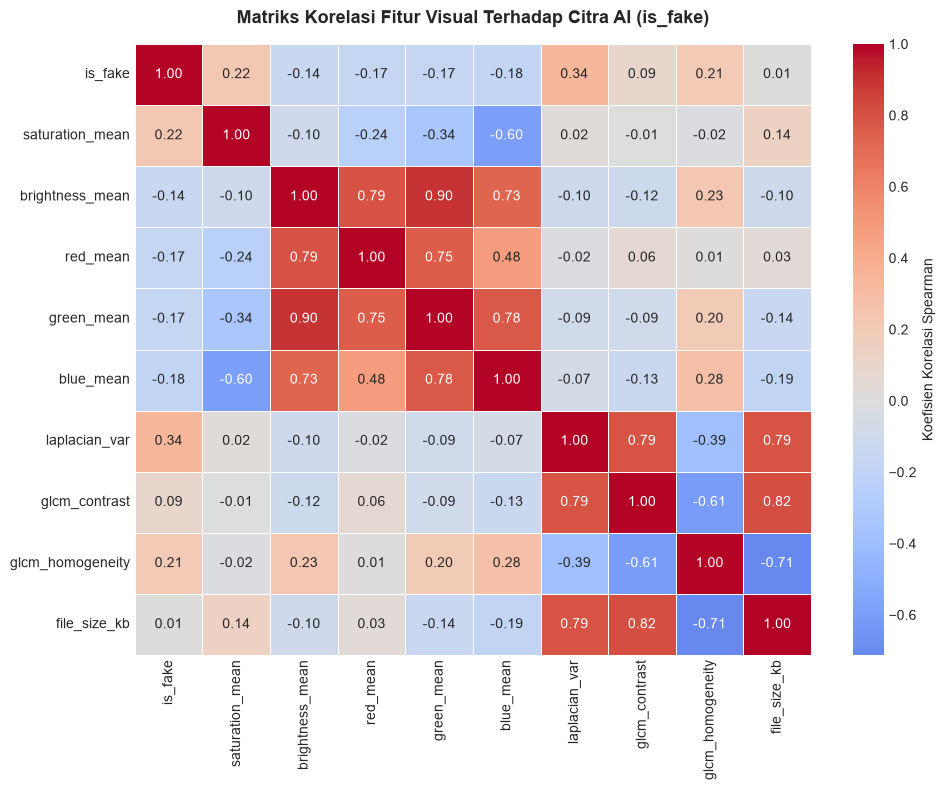

Grafik Heatmap berhasil disimpan di: C:\restu\intern 1\detection_image\outputs\visualizations\04_feature_correlation_heatmap.png


In [24]:
# 1. Buat kolom numerik untuk label: REAL = 0, FAKE = 1
df_features["is_fake"] = (df_features["label"] == "FAKE").astype(int)

# 2. Pilih fitur yang akan dihitung korelasinya
fitur_analisis = [
    'is_fake', 'saturation_mean', 'brightness_mean', 
    'red_mean', 'green_mean', 'blue_mean',
    'laplacian_var', 'glcm_contrast', 'glcm_homogeneity', 'file_size_kb'
]

# 3. Hitung matriks korelasi (Spearman Rank Correlation)
corr_matrix = df_features[fitur_analisis].corr(method='spearman')

# 4. Gambar Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, 
            linewidths=0.5, cbar_kws={'label': 'Koefisien Korelasi Spearman'})
plt.title("Matriks Korelasi Fitur Visual Terhadap Citra AI (is_fake)", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()

# Simpan grafik
save_path_heatmap = output_viz_dir / "04_feature_correlation_heatmap.png"
plt.savefig(save_path_heatmap, dpi=300)
plt.show()

print(f"Grafik Heatmap berhasil disimpan di: {save_path_heatmap.resolve()}")